## Landsat observed a warmer urban zone on all three dates {.smaller}

The contrast is the mean urban surface temperature minus the mean
temperature of the CORINE-based rural reference for each acquisition.

In [1]:
from pathlib import Path

import pandas as pd
import xarray as xr
from IPython.display import display

processed = Path("data/processed")
landsat_paths = sorted(processed.glob("landsat_*_analysis.nc"))
modis_path = processed / "modis_suhi_summary.csv"

if not landsat_paths:
    raise FileNotFoundError(f"No Landsat analysis files in {processed}")
if not modis_path.is_file():
    raise FileNotFoundError(f"Missing MODIS summary: {modis_path}")

modis = pd.read_csv(modis_path, parse_dates=["date"])

rows = []
for path in landsat_paths:
    with xr.open_dataset(path) as scene:
        scene_id = scene.attrs["scene_id"]
        date = pd.to_datetime(scene_id.split("_")[3], format="%Y%m%d")
        rows.append(
            {
                "Acquisition": date.strftime("%d %b %Y"),
                "Urban LST (°C)": scene["urban_mean"].item(),
                "Rural LST (°C)": scene["rural_mean"].item(),
                "SUHI (°C)": scene["suhi"].item(),
            }
        )

landsat_summary = pd.DataFrame(rows).sort_values("Acquisition", key=lambda dates: pd.to_datetime(dates, format="%d %b %Y"))
display(
    landsat_summary.rename(
        columns={
            "Acquisition": "Date",
            "Urban LST (°C)": "Urban",
            "Rural LST (°C)": "Rural",
            "SUHI (°C)": "SUHI",
        }
    )
    .style.hide(axis="index")
    .format({"Urban": "{:.2f}", "Rural": "{:.2f}", "SUHI": "{:+.2f}"})
)

Date,Urban,Rural,SUHI
05 Jun 2025,34.04,28.63,+5.42
21 Jun 2025,30.97,26.46,+4.51
16 Aug 2025,32.83,31.76,+1.07


## Where was the surface warmest on 5 June? {.smaller}

The anomaly subtracts the scene’s rural mean of **28.63 °C**.
Positive values show surfaces warmer than that reference.

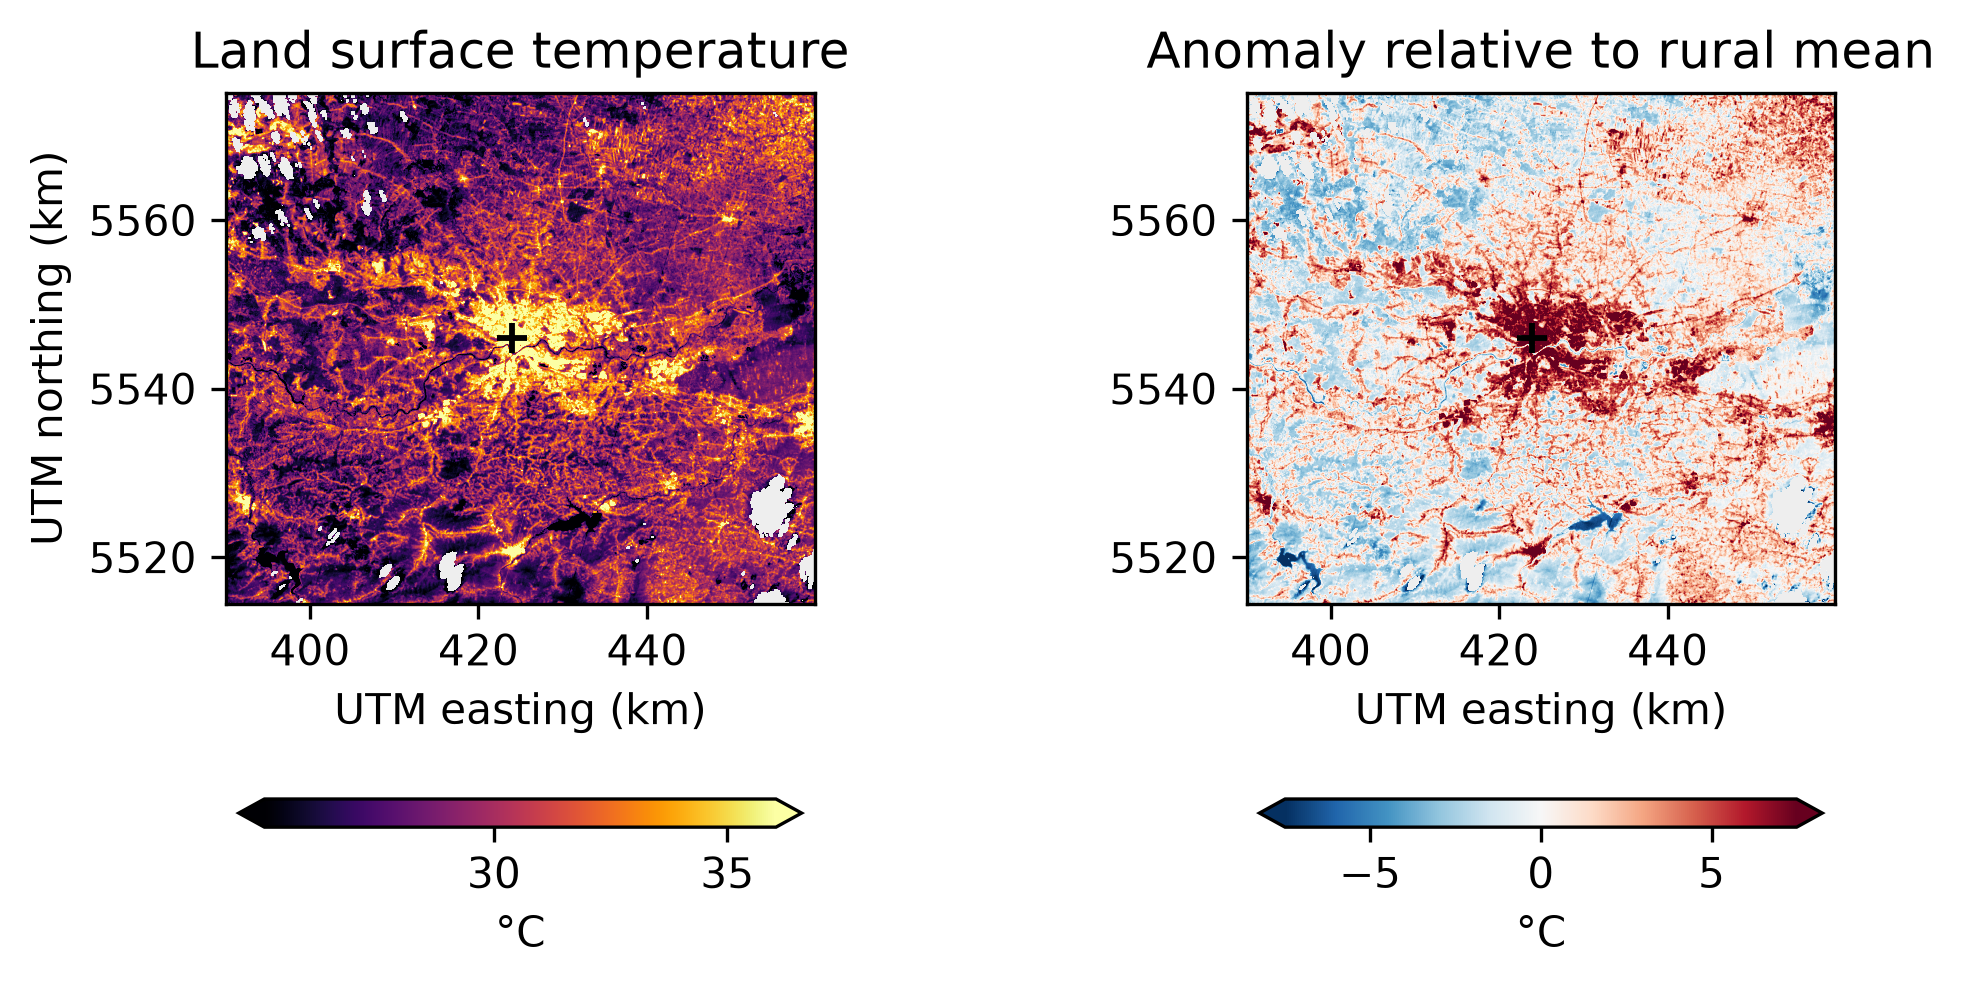

In [ ]:
#| fig-align: center

import matplotlib.pyplot as plt
import numpy as np
from rasterio.transform import Affine, array_bounds
from rasterio.warp import transform

june5_path = next(path for path in landsat_paths if "_20250605_" in path.name)

with xr.open_dataset(june5_path) as scene:
    lst = scene["lst"].values
    anomaly = scene["anomaly"].values
    affine = Affine(*scene.attrs["transform"])
    west, south, east, north = array_bounds(*lst.shape, affine)
    centre_x, centre_y = transform(
        "EPSG:4326", scene.attrs["crs"], [19.9372], [50.0617]
    )

extent_km = tuple(value / 1_000 for value in (west, east, south, north))
lst_low, lst_high = np.nanpercentile(lst, [2, 98])
anomaly_limit = np.nanpercentile(np.abs(anomaly), 98)

fig, axes = plt.subplots(
    1, 2, figsize=(10, 4.2), dpi=150, layout="constrained"
)

for ax, data, title, cmap, low, high in (
    (axes[0], lst, "Land surface temperature", "inferno", lst_low, lst_high),
    (axes[1], anomaly, "Anomaly relative to rural mean", "RdBu_r",
     -anomaly_limit, anomaly_limit),
):
    ax.set_facecolor("#eeeeee")
    image = ax.imshow(
        data, extent=extent_km, origin="upper", interpolation="nearest",
        cmap=cmap, vmin=low, vmax=high,
    )
    ax.plot(
        centre_x[0] / 1_000, centre_y[0] / 1_000,
        marker="+", color="black", markeredgewidth=1.4, markersize=7,
    )
    ax.set_title(title)
    ax.set_xlabel("UTM easting (km)")
    fig.colorbar(
        image, ax=ax, orientation="horizontal", label="°C",
        extend="both", fraction=0.055, pad=0.12,
    )

axes[0].set_ylabel("UTM northing (km)")
plt.show()

Cross = Kraków centre. Grey = missing LST. Colours saturate at the
display limits. The anomaly scale is symmetric around zero.

## Vegetated surfaces tended to be cooler on 5 June {.smaller}

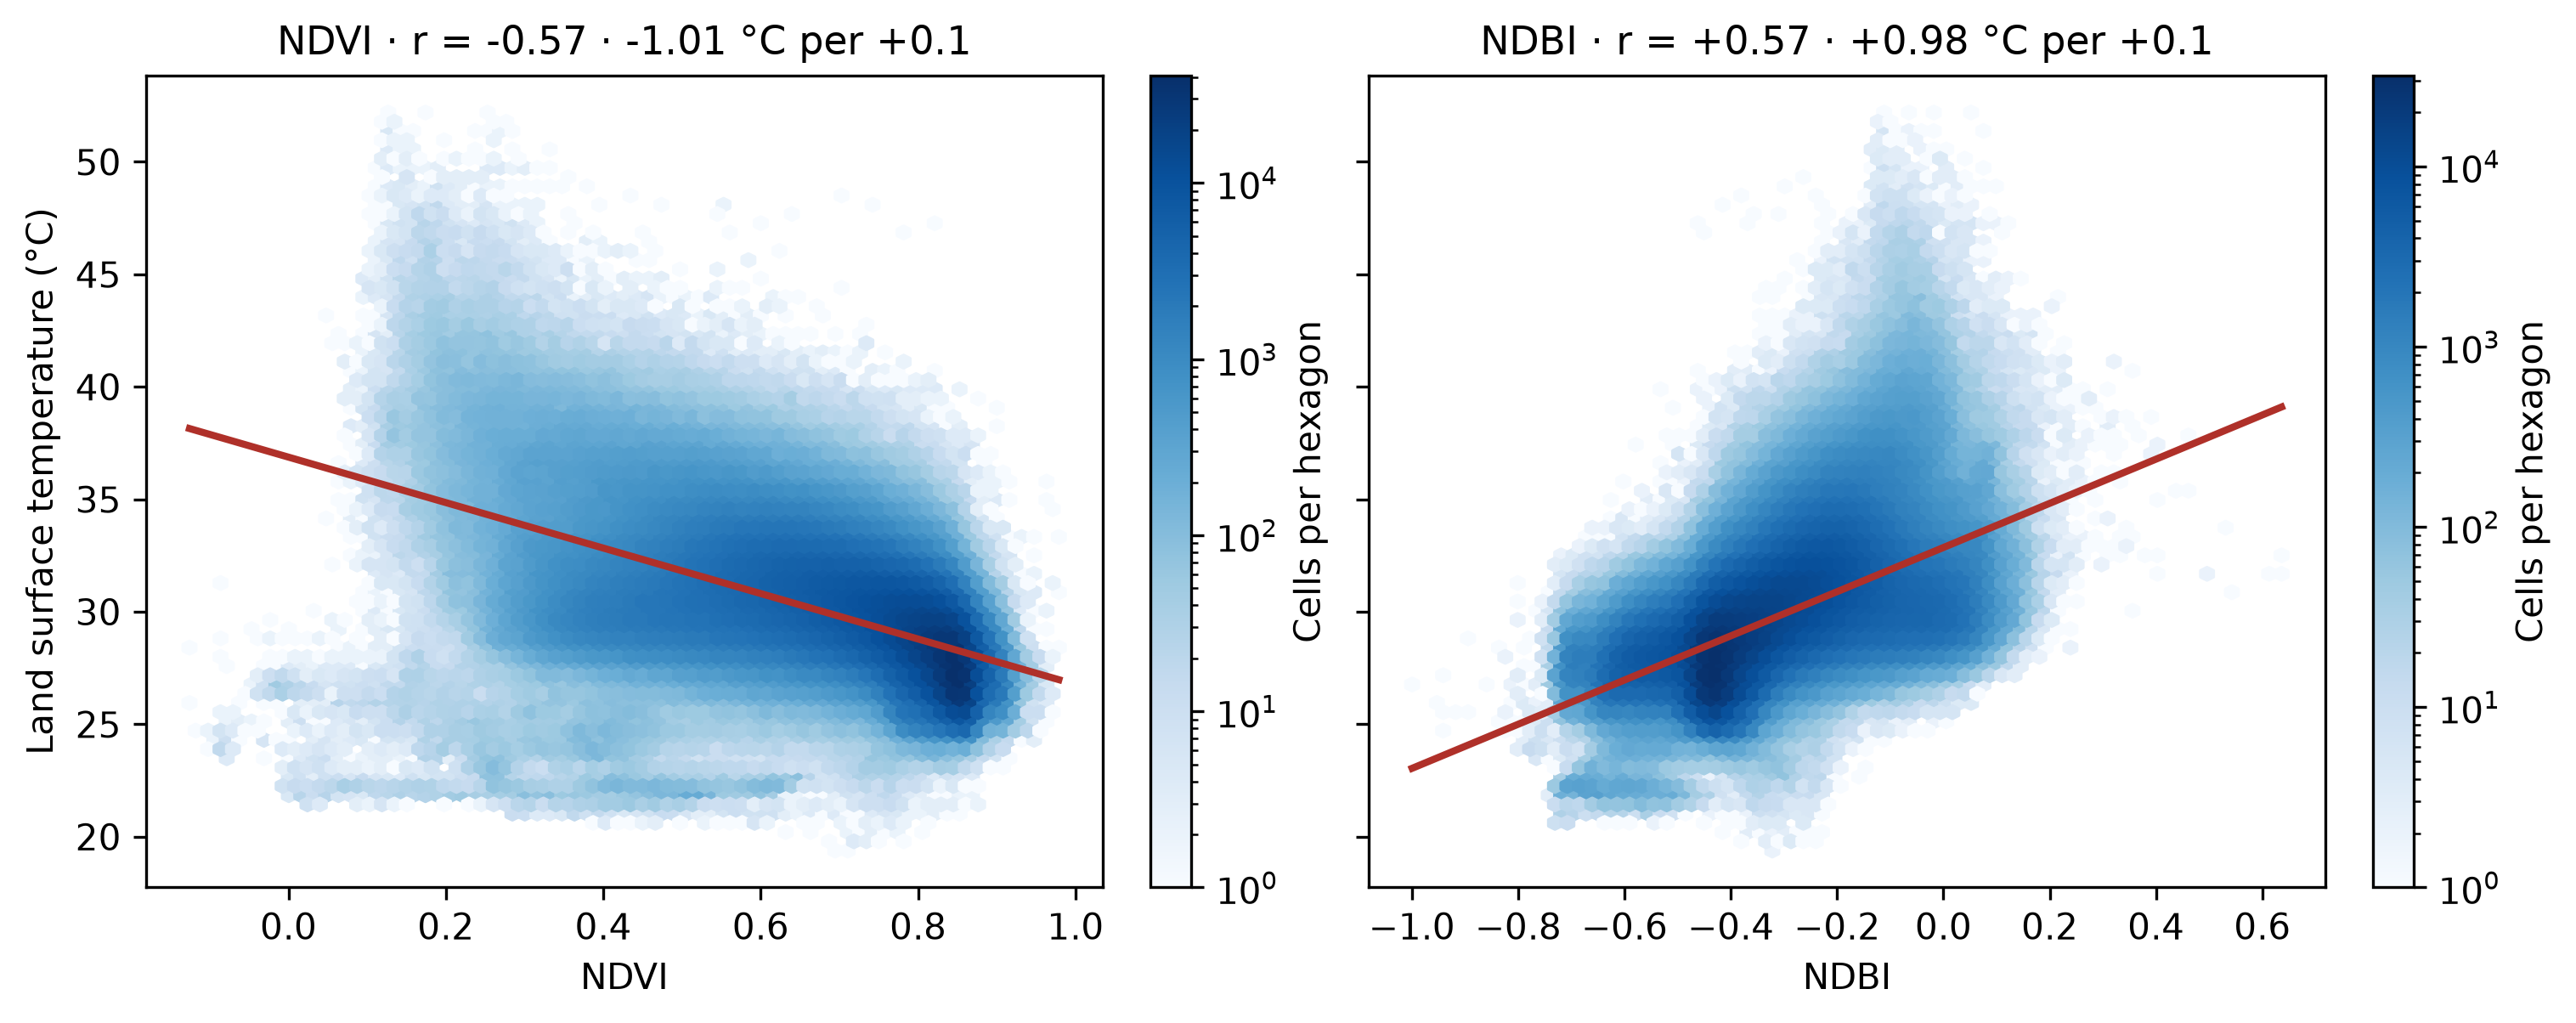

In [3]:
#| fig-align: center

with xr.open_dataset(june5_path) as scene:
    temperature = scene["lst"].values
    classified = scene["land_cover_code"].values != 0
    valid_temperature = classified & np.isfinite(temperature)

    fig, axes = plt.subplots(
        1, 2, figsize=(10, 3.9), dpi=150, sharey=True, layout="constrained"
    )

    for ax, name in zip(axes, ("ndvi", "ndbi")):
        index = scene[name].values
        valid = valid_temperature & np.isfinite(index)
        x = index[valid]
        y = temperature[valid]

        slope = scene["slope"].sel(index=name).item()
        intercept = scene["intercept"].sel(index=name).item()
        r = scene["pearson_r"].sel(index=name).item()
        n = scene["index_n_valid"].sel(index=name).item()
        assert x.size == n

        density = ax.hexbin(
            x, y, gridsize=70, bins="log", mincnt=1, cmap="Blues"
        )
        line_x = np.array([x.min(), x.max()])
        ax.plot(line_x, intercept + slope * line_x, color="#af3029", linewidth=2)
        ax.set_title(
            f"{name.upper()} · r = {r:+.2f} · {slope / 10:+.2f} °C per +0.1",
            fontsize=11,
        )
        ax.set_xlabel(name.upper())
        fig.colorbar(density, ax=ax, label="Cells per hexagon")

    axes[0].set_ylabel("Land surface temperature (°C)")
    plt.show()
    plt.close(fig)

Darker hexagons contain more cells. Red lines are the fitted regressions.
Both associations are descriptive and may also reflect differences in land cover,
moisture, and other surface conditions.